# Phase 3 — Reusable OCR Pipeline

## Objective

This notebook turns the experiments from `04a_ocr_foundations.ipynb` into a
reusable document-level pipeline.

The pipeline receives:

- one canonical RGB document;
- the corresponding template annotation;
- the source dimensions used by the annotation.

It returns raw predictions for all seven canonical fields.

Model loading remains outside the per-document function. Reloading the model
for every document would waste time and produce misleading latency
measurements.

Conceptual boundary:
```
load model once
      |
      v
canonical document + template annotation
      |
      v
seven padded crops
      |
      v
seven raw OCR predictions
      |
      v
document-level result
```

In [1]:
from pathlib import Path
import json

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from transformers import (
    GenerationConfig,
    TrOCRProcessor,
    VisionEncoderDecoderModel,
)


current_directory = Path.cwd().resolve()

if (current_directory / "PROJECT.md").is_file():
    repository_root = current_directory
elif (current_directory.parent / "PROJECT.md").is_file():
    repository_root = current_directory.parent
else:
    raise FileNotFoundError(
        "Start Jupyter from the repository root or notebooks directory."
    )

dataset_root = repository_root / "data" / "raw"

print("Repository root:", repository_root)
print("Dataset root:", dataset_root)

/home/raspiestchip/kyc-router/.venv/lib64/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Repository root: /home/raspiestchip/kyc-router
Dataset root: /home/raspiestchip/kyc-router/data/raw


In [2]:
phase_2_config_path = (
    repository_root
    / "configs"
    / "controlled_degradations_v1.json"
)

with phase_2_config_path.open(encoding="utf-8") as config_file:
    phase_2_config = json.load(config_file)

canonical_width = phase_2_config["canonical_width"]
canonical_height = phase_2_config["canonical_height"]

In [3]:
split_manifest_path = (
    repository_root
    / "splits"
    / "alb_id_v1.csv"
)

split_manifest = pd.read_csv(
    split_manifest_path,
    dtype={"sample_id": "string"},
)
split_counts = split_manifest["split"].value_counts()

assert len(split_manifest) == 100
assert split_manifest["identity_key"].is_unique
assert split_counts.to_dict() == {
    "train": 70,
    "validation": 15,
    "test": 15,
}

split_counts

split
train         70
validation    15
test          15
Name: count, dtype: int64

Let's load the OCR runtime now:

In [4]:
document_type = "alb_id"

raw_to_canonical_field = {
    "number": "document_number",
    "surname": "surname",
    "name": "given_names",
    "birth_date": "date_of_birth",
    "expiry_date": "expiry_date",
    "nationality": "nationality",
    "gender": "sex",
}

ocr_model_id = "microsoft/trocr-small-printed"
ocr_model_revision = (
    "04e994ab854b0089d4929f48c2b4dbe2ce78a340"
)

print("Required fields:", list(raw_to_canonical_field.values()))
print("OCR checkpoint:", ocr_model_id)
print("Revision:", ocr_model_revision)

Required fields: ['document_number', 'surname', 'given_names', 'date_of_birth', 'expiry_date', 'nationality', 'sex']
OCR checkpoint: microsoft/trocr-small-printed
Revision: 04e994ab854b0089d4929f48c2b4dbe2ce78a340


In [5]:
assert torch.cuda.is_available(), (
    "This notebook expects the validated CUDA environment."
)

inference_device = torch.device("cuda:0")

ocr_processor = TrOCRProcessor.from_pretrained(
    ocr_model_id,
    revision=ocr_model_revision,
)

ocr_generation_config = GenerationConfig.from_pretrained(
    ocr_model_id,
    revision=ocr_model_revision,
)

ocr_model = VisionEncoderDecoderModel.from_pretrained(
    ocr_model_id,
    revision=ocr_model_revision,
    dtype=torch.float32,
    use_safetensors=True,
)

ocr_model = ocr_model.to(inference_device)
ocr_model.eval()

assert next(ocr_model.parameters()).device == inference_device
assert ocr_model.training is False

print("Device:", inference_device)
print("GPU:", torch.cuda.get_device_name(0))
print("Model loaded in evaluation mode.")

Loading weights:   0%|          | 0/360 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 360/360 [00:00<00:00, 22275.57it/s]


[transformers] VisionEncoderDecoderModel LOAD REPORT from: microsoft/trocr-small-printed
Key                         | Status  | 
----------------------------+---------+-
encoder.pooler.dense.bias   | MISSING | 
encoder.pooler.dense.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Device: cuda:0
GPU: NVIDIA GeForce GTX 1650
Model loaded in evaluation mode.


## Data-loading boundary

The OCR pipeline should operate on images and canonical field metadata. It
should not contain MIDV directory paths or VIA JSON parsing logic.

We therefore separate:

1. A generic VIA loader that indexes annotation records by filename.
2. An `alb_id` adapter that loads the assets belonging to one identity.
3. The dataset-independent OCR pipeline that will consume those assets.

During development, the adapter refuses to load test identities.

In [6]:
def load_via_records_by_filename(annotation_path):
    with annotation_path.open(
        encoding="utf-8"
    ) as annotation_file:
        via_document = json.load(annotation_file)

    metadata = via_document["_via_img_metadata"]
    records = list(metadata.values())

    records_by_filename = {
        record["filename"]: record
        for record in records
    }

    if len(records_by_filename) != len(records):
        raise ValueError(
            f"Duplicate filenames in {annotation_path}"
        )

    return records_by_filename

In [7]:
template_annotation_path = (
    dataset_root
    / "templates"
    / "annotations"
    / f"{document_type}.json"
)

photo_annotation_path = (
    dataset_root
    / "photo"
    / "annotations"
    / f"{document_type}.json"
)

template_records_by_filename = (
    load_via_records_by_filename(
        template_annotation_path
    )
)

photo_records_by_filename = (
    load_via_records_by_filename(
        photo_annotation_path
    )
)

assert len(template_records_by_filename) == 100
assert len(photo_records_by_filename) == 100

print(
    "Template annotation records:",
    len(template_records_by_filename),
)

print(
    "Photo annotation records:",
    len(photo_records_by_filename),
)

Template annotation records: 100
Photo annotation records: 100


In [8]:
manifest_by_identity = split_manifest.set_index(
    "identity_key",
    verify_integrity=True,
)

manifest_by_identity.head()

/tmp/ipykernel_289511/327312918.py:1: Pandas4Warning: The 'verify_integrity' keyword in DataFrame.set_index is deprecated and will be removed in a future version. Directly check the result.index.is_unique instead.
  manifest_by_identity = split_manifest.set_index(


,document_type,sample_id,split,split_seed
identity_key,,,,
alb_id/38,alb_id,38,train,2026
alb_id/06,alb_id,06,train,2026
alb_id/77,alb_id,77,train,2026
alb_id/69,alb_id,69,train,2026
alb_id/02,alb_id,02,train,2026


In [9]:

def load_alb_id_assets(
    identity_key,
    *,
    manifest_index,
    dataset_root,
    template_record_index,
    photo_record_index,
):
    if identity_key not in manifest_index.index:
        raise KeyError(
            f"Unknown identity: {identity_key}"
        )

    manifest_row = manifest_index.loc[identity_key]

    split_name = manifest_row["split"]

    if split_name == "test":
        raise PermissionError(
            "Test identities are sealed during "
            "Phase 3 development."
        )

    identity_document_type = (
        manifest_row["document_type"]
    )

    if identity_document_type != "alb_id":
        raise ValueError(
            "Phase 3 supports only alb_id."
        )

    sample_id = str(manifest_row["sample_id"])
    filename = f"{sample_id}.jpg"

    template_image_path = (
        dataset_root
        / "templates"
        / "images"
        / identity_document_type
        / filename
    )

    photo_image_path = (
        dataset_root
        / "photo"
        / "images"
        / identity_document_type
        / filename
    )

    template_bgr = cv2.imread(
        str(template_image_path)
    )

    photo_bgr = cv2.imread(
        str(photo_image_path)
    )

    if template_bgr is None:
        raise FileNotFoundError(
            template_image_path
        )

    if photo_bgr is None:
        raise FileNotFoundError(
            photo_image_path
        )

    try:
        template_record = (
            template_record_index[filename]
        )

        photo_record = (
            photo_record_index[filename]
        )
    except KeyError as error:
        raise KeyError(
            f"Missing annotation for {filename}"
        ) from error

    return {
        "identity_key": identity_key,
        "split": split_name,
        "document_type": identity_document_type,
        "sample_id": sample_id,
        "filename": filename,
        "template_bgr": template_bgr,
        "photo_bgr": photo_bgr,
        "template_record": template_record,
        "photo_record": photo_record,
    }

Let's run one training identity:

In [10]:

training_identity_key = (
    split_manifest
    .loc[
        split_manifest["split"] == "train",
        "identity_key",
    ]
    .sort_values()
    .iloc[0]
)

training_assets = load_alb_id_assets(
    training_identity_key,
    manifest_index=manifest_by_identity,
    dataset_root=dataset_root,
    template_record_index=(
        template_records_by_filename
    ),
    photo_record_index=(
        photo_records_by_filename
    ),
)

print("Identity:", training_assets["identity_key"])
print("Split:", training_assets["split"])
print(
    "Template shape:",
    training_assets["template_bgr"].shape,
)
print(
    "Photograph shape:",
    training_assets["photo_bgr"].shape,
)

Identity: alb_id/02
Split: train
Template shape: (1360, 2167, 3)
Photograph shape: (4032, 2268, 3)


In [11]:

sealed_test_identity_key = (
    split_manifest
    .loc[
        split_manifest["split"] == "test",
        "identity_key",
    ]
    .sort_values()
    .iloc[0]
)

try:
    load_alb_id_assets(
        sealed_test_identity_key,
        manifest_index=manifest_by_identity,
        dataset_root=dataset_root,
        template_record_index=(
            template_records_by_filename
        ),
        photo_record_index=(
            photo_records_by_filename
        ),
    )
except PermissionError as error:
    print("Expected protection:", error)
else:
    raise AssertionError(
        "The test identity was not protected."
    )

Expected protection: Test identities are sealed during Phase 3 development.



## 3.4 Canonical document boundary

The OCR pipeline should not care whether a document originated from a clean
template or a photograph.

This function converts both sources into one canonical representation:

- RGB color order;
- `uint8` pixel values;
- fixed canonical dimensions;
- template annotation metadata for later field cropping.

Photographs require perspective rectification. Clean templates only require
resizing. Rectification normalizes geometry, but it does not remove blur,
glare, occlusion, or other real-world degradation.


In [12]:
def find_field_region(record, field_name):
    matching_regions = [
        region
        for region in record["regions"]
        if region["region_attributes"].get("field_name") == field_name
    ]

    if len(matching_regions) != 1:
        raise ValueError(
            f"Expected exactly one region named {field_name!r}, "
            f"found {len(matching_regions)}."
        )

    return matching_regions[0]


def extract_document_corners(photo_record):
    doc_quad_region = find_field_region(photo_record, "doc_quad")
    shape = doc_quad_region["shape_attributes"]

    document_corners = np.asarray(
        list(
            zip(
                shape["all_points_x"],
                shape["all_points_y"],
            )
        ),
        dtype=np.float32,
    )

    if document_corners.shape != (4, 2):
        raise ValueError(
            f"Expected four document corners, got {document_corners.shape}."
        )

    return document_corners


def rectify_document(
    photo_bgr,
    document_corners,
    output_width,
    output_height,
):
    destination_corners = np.asarray(
        [
            [0, 0],
            [output_width - 1, 0],
            [output_width - 1, output_height - 1],
            [0, output_height - 1],
        ],
        dtype=np.float32,
    )

    homography = cv2.getPerspectiveTransform(
        document_corners,
        destination_corners,
    )

    return cv2.warpPerspective(
        photo_bgr,
        homography,
        (output_width, output_height),
    )

# These functions represent the stable phase 2 geometry.

In [13]:
def make_canonical_observation(
    assets,
    source,
    output_width,
    output_height,
):
    if source == "template":
        canonical_bgr = cv2.resize(
            assets["template_bgr"],
            (output_width, output_height),
            interpolation=cv2.INTER_AREA,
        )

    elif source == "photo":
        document_corners = extract_document_corners(
            assets["photo_record"]
        )

        canonical_bgr = rectify_document(
            photo_bgr=assets["photo_bgr"],
            document_corners=document_corners,
            output_width=output_width,
            output_height=output_height,
        )

    else:
        raise ValueError(
            f"Unknown source {source!r}. Expected 'template' or 'photo'."
        )

    canonical_rgb = cv2.cvtColor(
        canonical_bgr,
        cv2.COLOR_BGR2RGB,
    )

    expected_shape = (output_height, output_width, 3)

    if canonical_rgb.shape != expected_shape:
        raise ValueError(
            f"Expected canonical shape {expected_shape}, "
            f"got {canonical_rgb.shape}."
        )

    if canonical_rgb.dtype != np.uint8:
        raise TypeError(
            f"Expected uint8 pixels, got {canonical_rgb.dtype}."
        )

    return {
        "identity_key": assets["identity_key"],
        "split": assets["split"],
        "source": source,
        "canonical_rgb": canonical_rgb,
        "template_record": assets["template_record"],
        "template_source_width": assets["template_bgr"].shape[1],
        "template_source_height": assets["template_bgr"].shape[0],
    }

In [14]:
training_template_observation = make_canonical_observation(
    assets=training_assets,
    source="template",
    output_width=canonical_width,
    output_height=canonical_height,
)

training_photo_observation = make_canonical_observation(
    assets=training_assets,
    source="photo",
    output_width=canonical_width,
    output_height=canonical_height,
)

for observation in [
    training_template_observation,
    training_photo_observation,
]:
    print(
        observation["source"],
        observation["canonical_rgb"].shape,
        observation["canonical_rgb"].dtype,
    )

template (680, 1084, 3) uint8
photo (680, 1084, 3) uint8


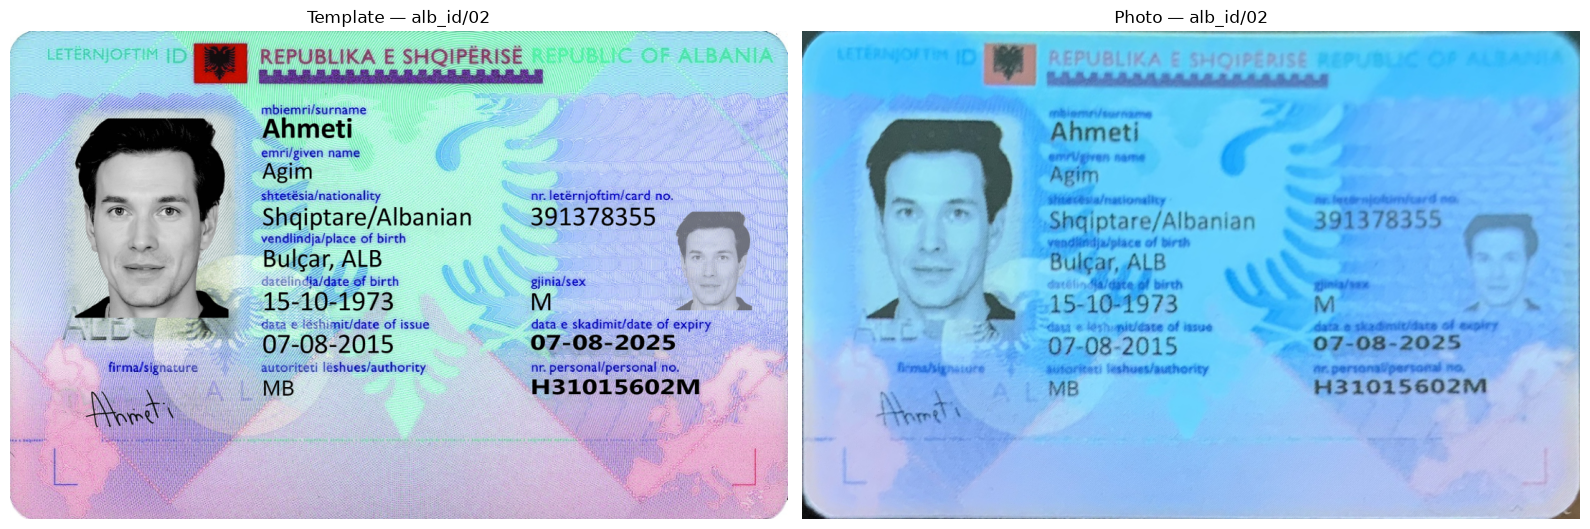

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for axis, observation in zip(
    axes,
    [
        training_template_observation,
        training_photo_observation,
    ],
):
    axis.imshow(observation["canonical_rgb"])
    axis.set_title(
        f'{observation["source"].title()} — '
        f'{observation["identity_key"]}'
    )
    axis.axis("off")

plt.tight_layout()
plt.show()

## 3.5 Extract canonical field crops

Field annotations are expressed in the clean template's original coordinate
system. We therefore:

1. scale each rectangle into canonical coordinates;
2. apply the Phase 2 padding policy;
3. clip the crop to the document boundaries;
4. retain its pixels, ground truth, rectangle, and crop bounds.

Keeping this metadata makes every OCR prediction traceable back to its input.

In [16]:
field_crop_config = {
    "padding_x": 0.10,
    "minimum_padding_x": 12,
    "padding_top": 0.10,
    "padding_bottom": 0.40,
}


def scale_field_shape(
    shape,
    source_width,
    source_height,
    target_width,
    target_height,
):
    return {
        "x": round(shape["x"] * target_width / source_width),
        "y": round(shape["y"] * target_height / source_height),
        "width": round(
            shape["width"] * target_width / source_width
        ),
        "height": round(
            shape["height"] * target_height / source_height
        ),
    }


def crop_field(
    image_rgb,
    shape,
    *,
    padding_x,
    minimum_padding_x,
    padding_top,
    padding_bottom,
):
    x = shape["x"]
    y = shape["y"]
    width = shape["width"]
    height = shape["height"]

    if width <= 0 or height <= 0:
        raise ValueError(f"Invalid field shape: {shape}")

    image_height, image_width = image_rgb.shape[:2]

    horizontal_padding = max(
        round(width * padding_x),
        minimum_padding_x,
    )
    top_padding = round(height * padding_top)
    bottom_padding = round(height * padding_bottom)

    bounds = {
        "x1": max(0, x - horizontal_padding),
        "y1": max(0, y - top_padding),
        "x2": min(
            image_width,
            x + width + horizontal_padding,
        ),
        "y2": min(
            image_height,
            y + height + bottom_padding,
        ),
    }

    crop_rgb = image_rgb[
        bounds["y1"]:bounds["y2"],
        bounds["x1"]:bounds["x2"],
    ].copy()

    if crop_rgb.size == 0:
        raise ValueError(
            f"Empty crop produced from shape {shape}."
        )

    return crop_rgb, bounds

In [17]:
def extract_field_crops(
    observation,
    field_mapping,
    crop_config,
):
    canonical_rgb = observation["canonical_rgb"]
    target_height, target_width = canonical_rgb.shape[:2]

    field_crops = {}

    for raw_field_name, canonical_field_name in field_mapping.items():
        field_region = find_field_region(
            observation["template_record"],
            raw_field_name,
        )

        field_attributes = field_region["region_attributes"]

        if "value" not in field_attributes:
            raise ValueError(
                f"Field {raw_field_name!r} has no ground-truth value."
            )

        canonical_shape = scale_field_shape(
            shape=field_region["shape_attributes"],
            source_width=observation["template_source_width"],
            source_height=observation["template_source_height"],
            target_width=target_width,
            target_height=target_height,
        )

        crop_rgb, crop_bounds = crop_field(
            image_rgb=canonical_rgb,
            shape=canonical_shape,
            **crop_config,
        )

        field_crops[canonical_field_name] = {
            "raw_field_name": raw_field_name,
            "canonical_field_name": canonical_field_name,
            "ground_truth": field_attributes["value"],
            "canonical_shape": canonical_shape,
            "crop_bounds": crop_bounds,
            "crop_rgb": crop_rgb,
        }

    return field_crops


In [18]:
training_template_field_crops = extract_field_crops(
    observation=training_template_observation,
    field_mapping=raw_to_canonical_field,
    crop_config=field_crop_config,
)

training_photo_field_crops = extract_field_crops(
    observation=training_photo_observation,
    field_mapping=raw_to_canonical_field,
    crop_config=field_crop_config,
)

assert set(training_template_field_crops) == set(
    raw_to_canonical_field.values()
)
assert set(training_photo_field_crops) == set(
    raw_to_canonical_field.values()
)

crop_summary_rows = []

for field_name in raw_to_canonical_field.values():
    template_field = training_template_field_crops[field_name]
    photo_field = training_photo_field_crops[field_name]

    assert (
        template_field["ground_truth"]
        == photo_field["ground_truth"]
    )

    crop_summary_rows.append(
        {
            "field": field_name,
            "ground_truth": template_field["ground_truth"],
            "template_shape": template_field[
                "crop_rgb"
            ].shape,
            "photo_shape": photo_field["crop_rgb"].shape,
            "crop_bounds": template_field["crop_bounds"],
        }
    )

crop_summary = pd.DataFrame(crop_summary_rows)
crop_summary

,field,ground_truth,template_shape,photo_shape,crop_bounds
0,document_number,391378355,"(39, 207, 3)","(39, 207, 3)","{'x1': 710, 'y1': 243, 'x2': 917, 'y2': 282}"
1,surname,Ahmeti,"(42, 152, 3)","(42, 152, 3)","{'x1': 339, 'y1': 118, 'x2': 491, 'y2': 160}"
2,given_names,Agim,"(36, 93, 3)","(36, 93, 3)","{'x1': 340, 'y1': 180, 'x2': 433, 'y2': 216}"
3,date_of_birth,15-10-1973,"(39, 216, 3)","(39, 216, 3)","{'x1': 336, 'y1': 361, 'x2': 552, 'y2': 400}"
4,expiry_date,07-08-2025,"(33, 239, 3)","(33, 239, 3)","{'x1': 708, 'y1': 421, 'x2': 947, 'y2': 454}"
5,nationality,Shqiptare/Albanian,"(39, 348, 3)","(39, 348, 3)","{'x1': 324, 'y1': 243, 'x2': 672, 'y2': 282}"
6,sex,M,"(36, 50, 3)","(36, 50, 3)","{'x1': 716, 'y1': 363, 'x2': 766, 'y2': 399}"


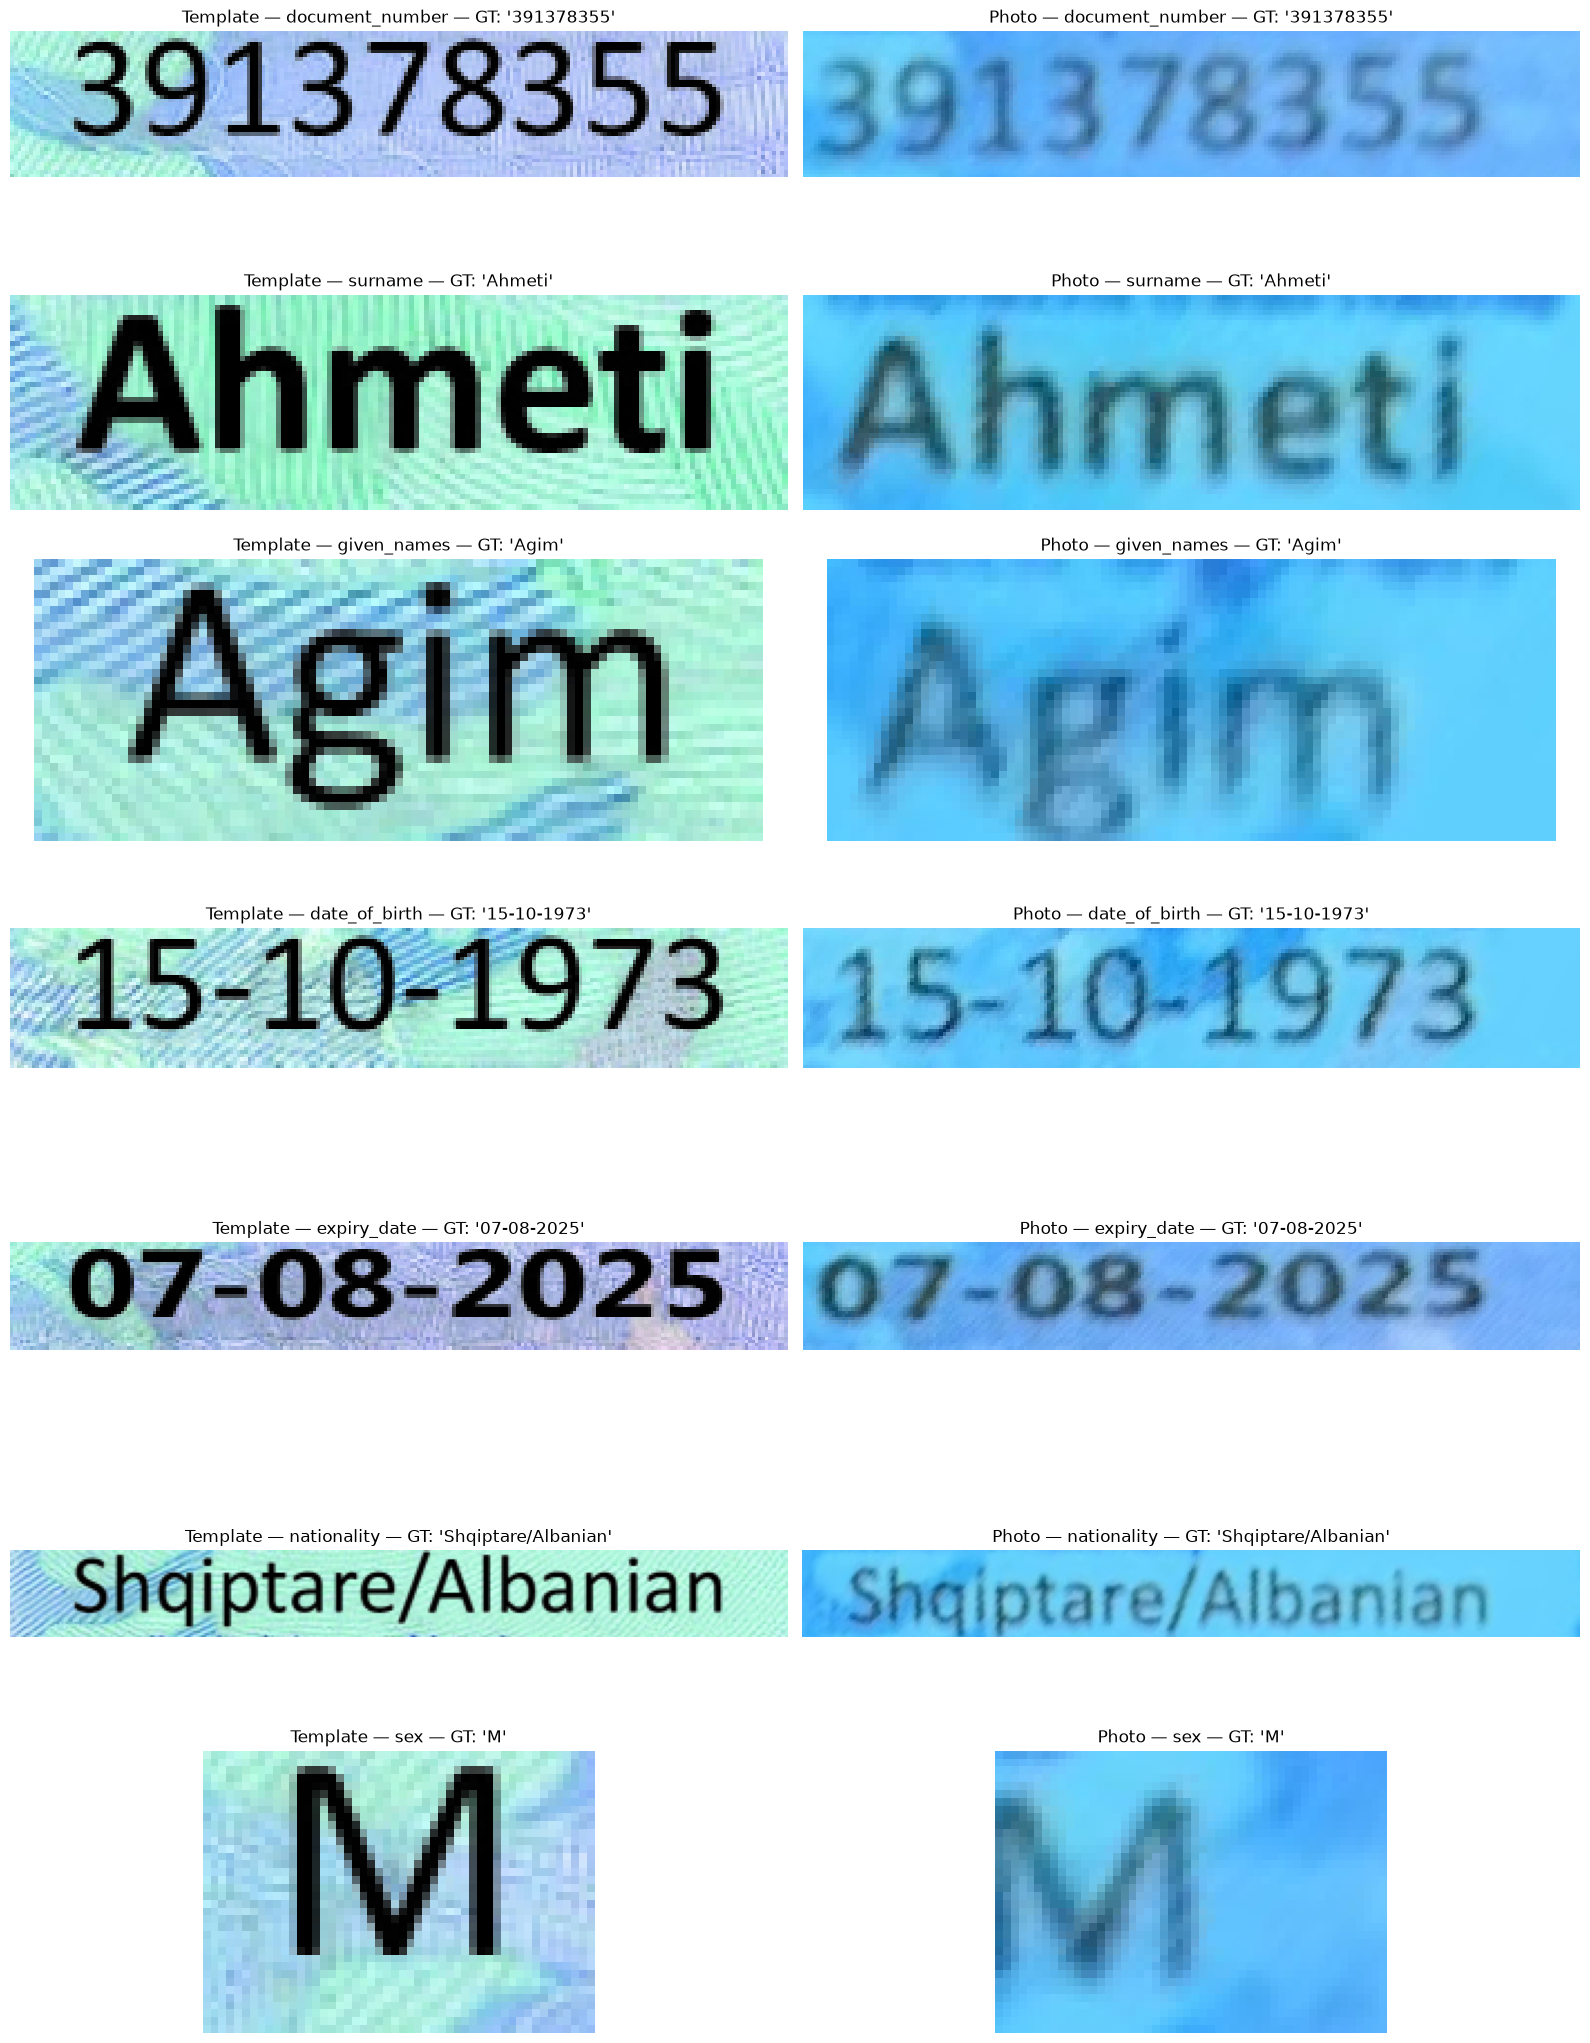

In [19]:

field_names = list(raw_to_canonical_field.values())

figure, axes = plt.subplots(
    len(field_names),
    2,
    figsize=(16, 3 * len(field_names)),
    squeeze=False,
)

for row_index, field_name in enumerate(field_names):
    template_field = training_template_field_crops[field_name]
    photo_field = training_photo_field_crops[field_name]

    axes[row_index, 0].imshow(template_field["crop_rgb"])
    axes[row_index, 0].set_title(
        f"Template — {field_name} — "
        f"GT: {template_field['ground_truth']!r}"
    )

    axes[row_index, 1].imshow(photo_field["crop_rgb"])
    axes[row_index, 1].set_title(
        f"Photo — {field_name} — "
        f"GT: {photo_field['ground_truth']!r}"
    )

    axes[row_index, 0].axis("off")
    axes[row_index, 1].axis("off")

plt.tight_layout()
plt.show()


## 3.6 Reusable OCR inference

Recognition has four operations:

1. the processor converts an RGB crop into model input tensors;
2. the tensor moves to the inference device;
3. the model generates token IDs autoregressively;
4. the processor decodes those IDs into text.

The function receives its dependencies explicitly instead of relying on hidden
global state. It retains the raw decoded prediction and inference metadata.
No normalization or semantic correction is applied yet.

In [20]:
def recognize_field_crop(
    crop_rgb,
    *,
    processor,
    model,
    device,
    generation_config,
):
    if crop_rgb.ndim != 3 or crop_rgb.shape[2] != 3:
        raise ValueError(
            f"Expected an RGB image, got shape {crop_rgb.shape}."
        )

    if crop_rgb.dtype != np.uint8:
        raise TypeError(
            f"Expected uint8 pixels, got {crop_rgb.dtype}."
        )

    if model.training:
        raise RuntimeError(
            "The OCR model is in training mode. Call model.eval() first."
        )

    pixel_values = processor(
        images=crop_rgb,
        return_tensors="pt",
    ).pixel_values.to(device)

    with torch.inference_mode():
        generated_ids = model.generate(
            pixel_values=pixel_values,
            generation_config=generation_config,
        )

    raw_prediction = processor.decode(
        generated_ids[0].detach().cpu(),
        skip_special_tokens=True,
        clean_up_tokenization_spaces=False,
    )

    return {
        "raw_prediction": raw_prediction,
        "generated_token_ids": (
            generated_ids[0].detach().cpu().tolist()
        ),
        "model_input_shape": tuple(pixel_values.shape),
        "model_input_dtype": str(pixel_values.dtype),
        "inference_device": str(pixel_values.device),
    }

In [21]:
def recognize_all_field_crops(
    field_crops,
    *,
    processor,
    model,
    device,
    generation_config,
):
    field_results = {}

    for field_name, field_data in field_crops.items():
        recognition = recognize_field_crop(
            crop_rgb=field_data["crop_rgb"],
            processor=processor,
            model=model,
            device=device,
            generation_config=generation_config,
        )

        field_results[field_name] = {
            "raw_field_name": field_data["raw_field_name"],
            "canonical_field_name": field_name,
            "ground_truth": field_data["ground_truth"],
            "canonical_shape": field_data["canonical_shape"],
            "crop_bounds": field_data["crop_bounds"],
            "crop_shape": field_data["crop_rgb"].shape,
            **recognition,
        }

    return field_results


Now let's run it on our template and photograph:

In [22]:
training_template_ocr_results = recognize_all_field_crops(
    field_crops=training_template_field_crops,
    processor=ocr_processor,
    model=ocr_model,
    device=inference_device,
    generation_config=ocr_generation_config,
)

training_photo_ocr_results = recognize_all_field_crops(
    field_crops=training_photo_field_crops,
    processor=ocr_processor,
    model=ocr_model,
    device=inference_device,
    generation_config=ocr_generation_config,
)

/home/raspiestchip/kyc-router/.venv/lib64/python3.14/site-packages/transformers/generation/utils.py:1955: UserWarning: Using the model-agnostic default `max_length` (=21) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


/home/raspiestchip/kyc-router/.venv/lib64/python3.14/site-packages/transformers/generation/utils.py:1955: UserWarning: Using the model-agnostic default `max_length` (=21) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


In [23]:
raw_result_rows = []

for field_name in raw_to_canonical_field.values():
    template_result = training_template_ocr_results[field_name]
    photo_result = training_photo_ocr_results[field_name]

    raw_result_rows.append(
        {
            "field": field_name,
            "ground_truth": template_result["ground_truth"],
            "template_prediction": template_result[
                "raw_prediction"
            ],
            "photo_prediction": photo_result["raw_prediction"],
            "template_raw_exact": (
                template_result["raw_prediction"]
                == template_result["ground_truth"]
            ),
            "photo_raw_exact": (
                photo_result["raw_prediction"]
                == photo_result["ground_truth"]
            ),
            "template_tokens": len(
                template_result["generated_token_ids"]
            ),
            "photo_tokens": len(
                photo_result["generated_token_ids"]
            ),
        }
    )

raw_results_table = pd.DataFrame(raw_result_rows)
raw_results_table

,field,ground_truth,template_prediction,photo_prediction,template_raw_exact,photo_raw_exact,template_tokens,photo_tokens
0,document_number,391378355,391378355,391378355,True,True,6,6
1,surname,Ahmeti,AHMETI,AHMETI,False,False,5,5
2,given_names,Agim,AGIM,AEIM,False,False,5,5
3,date_of_birth,15-10-1973,15-10-1973,15-10-1973,True,True,6,6
4,expiry_date,07-08-2025,07-08-2025,07-08-2025,True,True,6,6
5,nationality,Shqiptare/Albanian,SNAPTARE/ABANGAN,SHGIPTARE/ALBANIAN,False,False,9,11
6,sex,M,M,M,True,True,3,3


## 3.7 Compose the document OCR pipeline

The pipeline now has three stages:

1. canonicalize the source document;
2. extract the seven known field crops;
3. recognize each crop.

The orchestration function connects these stages and returns one structured
document result. The already-loaded processor and model are passed into it,
so checkpoint loading never occurs during document processing.


In [24]:
def ocr_canonical_observation(
    observation,
    *,
    field_mapping,
    crop_config,
    processor,
    model,
    device,
    generation_config,
):
    field_crops = extract_field_crops(
        observation=observation,
        field_mapping=field_mapping,
        crop_config=crop_config,
    )

    field_results = recognize_all_field_crops(
        field_crops=field_crops,
        processor=processor,
        model=model,
        device=device,
        generation_config=generation_config,
    )

    expected_fields = set(field_mapping.values())

    if set(field_results) != expected_fields:
        raise RuntimeError(
            "The OCR result does not contain exactly the "
            "required canonical fields."
        )

    return {
        "identity_key": observation["identity_key"],
        "split": observation["split"],
        "source": observation["source"],
        "canonical_shape": observation["canonical_rgb"].shape,
        "raw_predictions": {
            field_name: result["raw_prediction"]
            for field_name, result in field_results.items()
        },
        "fields": field_results,
    }


In [25]:
def run_document_ocr_pipeline(
    assets,
    *,
    source,
    output_width,
    output_height,
    field_mapping,
    crop_config,
    processor,
    model,
    device,
    generation_config,
):
    observation = make_canonical_observation(
        assets=assets,
        source=source,
        output_width=output_width,
        output_height=output_height,
    )

    return ocr_canonical_observation(
        observation=observation,
        field_mapping=field_mapping,
        crop_config=crop_config,
        processor=processor,
        model=model,
        device=device,
        generation_config=generation_config,
    )

In [26]:
training_template_pipeline_result = run_document_ocr_pipeline(
    assets=training_assets,
    source="template",
    output_width=canonical_width,
    output_height=canonical_height,
    field_mapping=raw_to_canonical_field,
    crop_config=field_crop_config,
    processor=ocr_processor,
    model=ocr_model,
    device=inference_device,
    generation_config=ocr_generation_config,
)

training_photo_pipeline_result = run_document_ocr_pipeline(
    assets=training_assets,
    source="photo",
    output_width=canonical_width,
    output_height=canonical_height,
    field_mapping=raw_to_canonical_field,
    crop_config=field_crop_config,
    processor=ocr_processor,
    model=ocr_model,
    device=inference_device,
    generation_config=ocr_generation_config,
)

/home/raspiestchip/kyc-router/.venv/lib64/python3.14/site-packages/transformers/generation/utils.py:1955: UserWarning: Using the model-agnostic default `max_length` (=21) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


In [27]:
assert (
    training_template_pipeline_result["raw_predictions"]
    == {
        field_name: result["raw_prediction"]
        for field_name, result
        in training_template_ocr_results.items()
    }
)

assert (
    training_photo_pipeline_result["raw_predictions"]
    == {
        field_name: result["raw_prediction"]
        for field_name, result
        in training_photo_ocr_results.items()
    }
)

pipeline_comparison = pd.DataFrame(
    [
        {
            "field": field_name,
            "ground_truth": (
                training_template_pipeline_result["fields"]
                [field_name]["ground_truth"]
            ),
            "template_prediction": (
                training_template_pipeline_result[
                    "raw_predictions"
                ][field_name]
            ),
            "photo_prediction": (
                training_photo_pipeline_result[
                    "raw_predictions"
                ][field_name]
            ),
        }
        for field_name in raw_to_canonical_field.values()
    ]
)

pipeline_comparison

,field,ground_truth,template_prediction,photo_prediction
0,document_number,391378355,391378355,391378355
1,surname,Ahmeti,AHMETI,AHMETI
2,given_names,Agim,AGIM,AEIM
3,date_of_birth,15-10-1973,15-10-1973,15-10-1973
4,expiry_date,07-08-2025,07-08-2025,07-08-2025
5,nationality,Shqiptare/Albanian,SNAPTARE/ABANGAN,SHGIPTARE/ALBANIAN
6,sex,M,M,M


## 3.8 Multi-identity pipeline check

We will process three training identities using both:

- the clean template;
- the rectified photograph.

This produces:

3 identities × 2 sources × 7 fields = 42 OCR operations.

The resulting metrics are development diagnostics, not final benchmark results.
Validation and test data remain untouched.

In [28]:
training_manifest_rows = (
    split_manifest.loc[
        (split_manifest["document_type"] == document_type)
        & (split_manifest["split"] == "train")
    ]
    .sort_values("identity_key")
    .reset_index(drop=True)
)

selected_training_identity_keys = (
    training_manifest_rows["identity_key"]
    .head(3)
    .tolist()
)

selected_training_identity_keys

['alb_id/02', 'alb_id/03', 'alb_id/04']

In [29]:
def run_pipeline_sample(
    identity_keys,
    *,
    sources,
    manifest_index,
    dataset_root,
    template_records_by_filename,
    photo_records_by_filename,
    output_width,
    output_height,
    field_mapping,
    crop_config,
    processor,
    model,
    device,
    generation_config,
):
    document_results = []

    for identity_key in identity_keys:
        assets = load_alb_id_assets(
            identity_key=identity_key,
            manifest_index=manifest_index,
            dataset_root=dataset_root,
            template_record_index=(
                template_records_by_filename
            ),
            photo_record_index=(
                photo_records_by_filename
            ),
        )

        if assets["split"] != "train":
            raise PermissionError(
                f"Expected training data, but {identity_key!r} "
                f"belongs to {assets['split']!r}."
            )

        for source in sources:
            print(f"Running {identity_key} — {source}")

            result = run_document_ocr_pipeline(
                assets=assets,
                source=source,
                output_width=output_width,
                output_height=output_height,
                field_mapping=field_mapping,
                crop_config=crop_config,
                processor=processor,
                model=model,
                device=device,
                generation_config=generation_config,
            )

            document_results.append(result)

    return document_results

In [30]:

sample_pipeline_results = run_pipeline_sample(
    identity_keys=selected_training_identity_keys,
    sources=("template", "photo"),
    manifest_index=manifest_by_identity,
    dataset_root=dataset_root,
    template_records_by_filename=template_records_by_filename,
    photo_records_by_filename=photo_records_by_filename,
    output_width=canonical_width,
    output_height=canonical_height,
    field_mapping=raw_to_canonical_field,
    crop_config=field_crop_config,
    processor=ocr_processor,
    model=ocr_model,
    device=inference_device,
    generation_config=ocr_generation_config,
)

assert len(sample_pipeline_results) == 6

Running alb_id/02 — template


/home/raspiestchip/kyc-router/.venv/lib64/python3.14/site-packages/transformers/generation/utils.py:1955: UserWarning: Using the model-agnostic default `max_length` (=21) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


Running alb_id/02 — photo


Running alb_id/03 — template


Running alb_id/03 — photo


Running alb_id/04 — template


Running alb_id/04 — photo


In [31]:
def flatten_pipeline_results(document_results):
    rows = []

    for document_result in document_results:
        for field_name, field_result in (
            document_result["fields"].items()
        ):
            raw_prediction = field_result["raw_prediction"]
            ground_truth = field_result["ground_truth"]

            rows.append(
                {
                    "identity_key": document_result[
                        "identity_key"
                    ],
                    "split": document_result["split"],
                    "source": document_result["source"],
                    "field": field_name,
                    "raw_field": field_result[
                        "raw_field_name"
                    ],
                    "ground_truth": ground_truth,
                    "raw_prediction": raw_prediction,
                    "raw_exact_match": (
                        raw_prediction == ground_truth
                    ),
                    "crop_shape": field_result["crop_shape"],
                    "generated_token_count": len(
                        field_result[
                            "generated_token_ids"
                        ]
                    ),
                }
            )

    return pd.DataFrame(rows)


sample_raw_results = flatten_pipeline_results(
    sample_pipeline_results
)

assert len(sample_raw_results) == 42
assert set(sample_raw_results["split"]) == {"train"}

sample_raw_results

,identity_key,split,source,field,raw_field,ground_truth,raw_prediction,raw_exact_match,crop_shape,generated_token_count
0,alb_id/02,train,template,document_number,number,391378355,391378355,True,"(39, 207, 3)",6
1,alb_id/02,train,template,surname,surname,Ahmeti,AHMETI,False,"(42, 152, 3)",5
2,alb_id/02,train,template,given_names,name,Agim,AGIM,False,"(36, 93, 3)",5
3,alb_id/02,train,template,date_of_birth,birth_date,15-10-1973,15-10-1973,True,"(39, 216, 3)",6
4,alb_id/02,train,template,expiry_date,expiry_date,07-08-2025,07-08-2025,True,"(33, 239, 3)",6
5,alb_id/02,train,template,nationality,nationality,Shqiptare/Albanian,SNAPTARE/ABANGAN,False,"(39, 348, 3)",9
6,alb_id/02,train,template,sex,gender,M,M,True,"(36, 50, 3)",3
7,alb_id/02,train,photo,document_number,number,391378355,391378355,True,"(39, 207, 3)",6
8,alb_id/02,train,photo,surname,surname,Ahmeti,AHMETI,False,"(42, 152, 3)",5
9,alb_id/02,train,photo,given_names,name,Agim,AEIM,False,"(36, 93, 3)",5


In [32]:
sample_raw_summary = (
    sample_raw_results
    .groupby(["source", "field"], as_index=False)
    .agg(
        samples=("raw_exact_match", "size"),
        raw_exact_matches=("raw_exact_match", "sum"),
        raw_exact_rate=("raw_exact_match", "mean"),
    )
)

sample_raw_summary


,source,field,samples,raw_exact_matches,raw_exact_rate
0,photo,date_of_birth,3,3,1.000000
1,photo,document_number,3,3,1.000000
2,photo,expiry_date,3,2,0.666667
3,photo,given_names,3,0,0.000000
4,photo,nationality,3,0,0.000000
5,photo,sex,3,3,1.000000
6,photo,surname,3,0,0.000000
7,template,date_of_birth,3,2,0.666667
8,template,document_number,3,3,1.000000
9,template,expiry_date,3,2,0.666667


In [33]:
sample_raw_mismatches = (
    sample_raw_results.loc[
        ~sample_raw_results["raw_exact_match"],
        [
            "identity_key",
            "source",
            "field",
            "ground_truth",
            "raw_prediction",
        ],
    ]
    .sort_values(["field", "identity_key", "source"])
    .reset_index(drop=True)
)

sample_raw_mismatches


,identity_key,source,field,ground_truth,raw_prediction
0,alb_id/04,template,date_of_birth,21-03-1985,21 03-1985
1,alb_id/04,photo,expiry_date,09-06-2028,09-06-2018
2,alb_id/04,template,expiry_date,09-06-2028,09-06-2018
3,alb_id/02,photo,given_names,Agim,AEIM
4,alb_id/02,template,given_names,Agim,AGIM
5,alb_id/03,photo,given_names,Agon,ASON
6,alb_id/03,template,given_names,Agon,AGON
7,alb_id/04,photo,given_names,Agron,AERON
8,alb_id/04,template,given_names,Agron,AKRON
9,alb_id/02,photo,nationality,Shqiptare/Albanian,SHGIPTARE/ALBANIAN


## Workshop 3 checkpoint

The pipeline now handles clean templates and rectified photographs through the
same canonical interface.

The sample reveals three error categories:

1. **Presentation differences**
   - `Ahmeti → AHMETI`
   - Raw exact match fails, although the text content is correct.
   - Case normalization can handle this safely.

2. **Potentially parseable formatting errors**
   - `21-03-1985 → 21 03-1985`
   - A controlled date parser may recover this, but only through explicitly
     documented accepted formats.

3. **Real recognition errors**
   - `2028 → 2018`
   - `Agim → AEIM`
   - `Shqiptare/Albanian → SNAPTARE/ABANGAN`
   - Normalization must not invent corrections for these errors.

Nationality is a systematic weakness across both source types, suggesting
checkpoint/domain mismatch rather than an isolated photograph problem.

Raw exact match substantially understates name and surname performance because
the checkpoint commonly produces uppercase text. This demonstrates why raw
predictions, normalized comparisons, and genuine OCR errors must remain
separate.

# Workshop 4 — Normalization and semantic validation

## 4.1 Common text normalization

Normalization removes harmless representation differences. It must not guess
what the OCR model intended.

Common normalization performs:

1. missing values remain `None`;
2. other values are converted to strings;
3. Unicode is normalized to NFC;
4. surrounding whitespace is removed;
5. internal whitespace is collapsed;
6. Unicode-aware case folding is applied.

Diacritics and punctuation are preserved. An empty string is also distinct
from a missing value.

In [34]:
import unicodedata


def is_missing_scalar(value):
    if value is None:
        return True

    missing_result = pd.isna(value)

    return isinstance(
        missing_result,
        (bool, np.bool_),
    ) and bool(missing_result)


def normalize_common_text(value):
    if is_missing_scalar(value):
        return None

    text = unicodedata.normalize(
        "NFC",
        str(value),
    )

    text = " ".join(text.split())

    return text.casefold()

In [35]:
common_normalization_examples = pd.DataFrame(
    [
        {
            "description": "case and surrounding whitespace",
            "raw": "  AHMETI  ",
            "expected": "ahmeti",
        },
        {
            "description": "internal whitespace",
            "raw": "Agim\n\tAhmeti",
            "expected": "agim ahmeti",
        },
        {
            "description": "bilingual punctuation",
            "raw": "Shqiptare/ALBANIAN",
            "expected": "shqiptare/albanian",
        },
        {
            "description": "decomposed Unicode accent",
            "raw": "Cafe\u0301",
            "expected": "café",
        },
        {
            "description": "punctuation is preserved",
            "raw": "D'Arcy-Smith",
            "expected": "d'arcy-smith",
        },
        {
            "description": "non-string value",
            "raw": 391378355,
            "expected": "391378355",
        },
        {
            "description": "missing value",
            "raw": None,
            "expected": None,
        },
        {
            "description": "empty but not missing",
            "raw": "   ",
            "expected": "",
        },
    ]
)

common_normalization_examples["actual"] = (
    common_normalization_examples["raw"].map(
        normalize_common_text
    )
)

actual_values = common_normalization_examples["actual"]
expected_values = common_normalization_examples["expected"]

common_normalization_examples["passed"] = (
    actual_values.eq(expected_values)
    | (
        actual_values.isna()
        & expected_values.isna()
    )
)

assert common_normalization_examples["passed"].all()

In [36]:
assert (
    normalize_common_text("José")
    != normalize_common_text("Jose")
)

assert (
    normalize_common_text("Shqiptare/Albanian")
    != normalize_common_text("Shqiptare Albanian")
)

assert (
    normalize_common_text("2028")
    != normalize_common_text("2018")
)

print("Meaningful differences were preserved.")


Meaningful differences were preserved.



## 4.2 Non-date field normalization

Field-specific normalization builds on common normalization:

- surname, given names, and nationality receive only common normalization;
- document numbers additionally remove whitespace and use uppercase;
- sex additionally uses uppercase.

Normalization does not validate meaning. For example, `male` becomes `MALE`,
not `M`. Validation will later report that `MALE` violates the schema.
Likewise, document-number characters such as `O` and `0` are never exchanged.

In [37]:
common_only_fields = frozenset(
    {
        "surname",
        "given_names",
        "nationality",
    }
)


def normalize_document_number(value):
    normalized_value = normalize_common_text(value)

    if normalized_value is None:
        return None

    without_whitespace = "".join(
        normalized_value.split()
    )

    return without_whitespace.upper()


def normalize_sex(value):
    normalized_value = normalize_common_text(value)

    if normalized_value is None:
        return None

    return normalized_value.upper()


def normalize_non_date_field(field_name, value):
    if field_name in common_only_fields:
        return normalize_common_text(value)

    if field_name == "document_number":
        return normalize_document_number(value)

    if field_name == "sex":
        return normalize_sex(value)

    raise ValueError(
        f"{field_name!r} is not a supported non-date field."
    )

In [38]:
def scalar_values_equal(left, right):
    left_missing = is_missing_scalar(left)
    right_missing = is_missing_scalar(right)

    if left_missing and right_missing:
        return True

    if left_missing or right_missing:
        return False

    return left == right

In [39]:

non_date_normalization_examples = pd.DataFrame(
    [
        {
            "field": "surname",
            "raw": "  AHMETI ",
            "expected": "ahmeti",
        },
        {
            "field": "given_names",
            "raw": "  José  Manuel ",
            "expected": "josé manuel",
        },
        {
            "field": "nationality",
            "raw": "Shqiptare/ALBANIAN",
            "expected": "shqiptare/albanian",
        },
        {
            "field": "document_number",
            "raw": " ab 12 34 ",
            "expected": "AB1234",
        },
        {
            "field": "document_number",
            "raw": "o0-i1",
            "expected": "O0-I1",
        },
        {
            "field": "sex",
            "raw": " m ",
            "expected": "M",
        },
        {
            "field": "sex",
            "raw": "male",
            "expected": "MALE",
        },
        {
            "field": "surname",
            "raw": None,
            "expected": None,
        },
    ]
)

non_date_normalization_examples["actual"] = [
    normalize_non_date_field(
        field_name=row.field,
        value=row.raw,
    )
    for row in non_date_normalization_examples.itertuples()
]

non_date_normalization_examples["passed"] = [
    scalar_values_equal(actual, expected)
    for actual, expected in zip(
        non_date_normalization_examples["actual"],
        non_date_normalization_examples["expected"],
    )
]

assert non_date_normalization_examples["passed"].all()

non_date_normalization_examples

,field,raw,expected,actual,passed
0,surname,AHMETI,ahmeti,ahmeti,True
1,given_names,José Manuel,josé manuel,josé manuel,True
2,nationality,Shqiptare/ALBANIAN,shqiptare/albanian,shqiptare/albanian,True
3,document_number,ab 12 34,AB1234,AB1234,True
4,document_number,o0-i1,O0-I1,O0-I1,True
5,sex,m,M,M,True
6,sex,male,MALE,MALE,True
7,surname,NaN,NaN,NaN,True


## 4.3 Explicit date normalization

Dates must be parsed through an explicit allowlist. We do not use locale
guessing or natural-language parsing.

Successfully parsed dates become `YYYY-MM-DD`. Missing values remain `None`.
Unparseable values remain as commonly normalized text so that the original
failure stays inspectable. Validation and scoring will ensure that invalid
dates cannot receive Exact Match credit.


In [40]:
import re
from datetime import datetime


supported_date_patterns = (
    (
        re.compile(r"^\d{2}-\d{2}-\d{4}$"),
        "%d-%m-%Y",
    ),
    (
        re.compile(r"^\d{2}/\d{2}/\d{4}$"),
        "%d/%m/%Y",
    ),
    (
        re.compile(r"^\d{2}\.\d{2}\.\d{4}$"),
        "%d.%m.%Y",
    ),
    (
        re.compile(r"^\d{4}-\d{2}-\d{2}$"),
        "%Y-%m-%d",
    ),
)


def parse_supported_date_text(normalized_text):
    for pattern, date_format in supported_date_patterns:
        if not pattern.fullmatch(normalized_text):
            continue

        try:
            return datetime.strptime(
                normalized_text,
                date_format,
            ).date()
        except ValueError:
            return None

    return None


def normalize_date(value):
    normalized_text = normalize_common_text(value)

    if normalized_text is None:
        return None

    parsed_date = parse_supported_date_text(
        normalized_text
    )

    if parsed_date is None:
        return normalized_text

    return parsed_date.isoformat()

In [41]:
date_normalization_examples = pd.DataFrame(
    [
        {
            "raw": "15-10-1973",
            "expected": "1973-10-15",
            "expected_parseable": True,
        },
        {
            "raw": "15/10/1973",
            "expected": "1973-10-15",
            "expected_parseable": True,
        },
        {
            "raw": "15.10.1973",
            "expected": "1973-10-15",
            "expected_parseable": True,
        },
        {
            "raw": "1973-10-15",
            "expected": "1973-10-15",
            "expected_parseable": True,
        },
        {
            "raw": "31-02-2024",
            "expected": "31-02-2024",
            "expected_parseable": False,
        },
        {
            "raw": "21 03-1985",
            "expected": "21 03-1985",
            "expected_parseable": False,
        },
        {
            "raw": "09-06-2018",
            "expected": "2018-06-09",
            "expected_parseable": True,
        },
        {
            "raw": "15–10–1973",
            "expected": "15–10–1973",
            "expected_parseable": False,
        },
        {
            "raw": None,
            "expected": None,
            "expected_parseable": False,
        },
    ]
)

date_normalization_examples["actual"] = [
    normalize_date(row.raw)
    for row in date_normalization_examples.itertuples()
]

date_normalization_examples["parseable"] = [
    (
        False
        if is_missing_scalar(row.raw)
        else parse_supported_date_text(
            normalize_common_text(row.raw)
        )
        is not None
    )
    for row in date_normalization_examples.itertuples()
]

date_normalization_examples["value_passed"] = [
    scalar_values_equal(actual, expected)
    for actual, expected in zip(
        date_normalization_examples["actual"],
        date_normalization_examples["expected"],
    )
]

date_normalization_examples["parse_passed"] = (
    date_normalization_examples["parseable"]
    == date_normalization_examples["expected_parseable"]
)

assert date_normalization_examples["value_passed"].all()
assert date_normalization_examples["parse_passed"].all()

date_normalization_examples

,raw,expected,expected_parseable,actual,parseable,value_passed,parse_passed
0,15-10-1973,1973-10-15,True,1973-10-15,True,True,True
1,15/10/1973,1973-10-15,True,1973-10-15,True,True,True
2,15.10.1973,1973-10-15,True,1973-10-15,True,True,True
3,1973-10-15,1973-10-15,True,1973-10-15,True,True,True
4,31-02-2024,31-02-2024,False,31-02-2024,False,True,True
5,21 03-1985,21 03-1985,False,21 03-1985,False,True,True
6,09-06-2018,2018-06-09,True,2018-06-09,True,True,True
7,15–10–1973,15–10–1973,False,15–10–1973,False,True,True
8,NaN,NaN,False,NaN,False,True,True


## 4.4 Unified field normalization

A single dispatcher applies the correct rule based only on the canonical field
name. It does not know whether its input came from OCR, another model, or
ground truth.

This separation makes normalization shared, deterministic, and independently
testable.


In [42]:
date_fields = frozenset(
    {
        "date_of_birth",
        "expiry_date",
    }
)

required_field_names = tuple(
    raw_to_canonical_field.values()
)

assert len(required_field_names) == 7
assert len(set(required_field_names)) == 7


def normalize_field_value(field_name, value):
    if field_name not in required_field_names:
        raise ValueError(
            f"Unknown canonical field: {field_name!r}"
        )

    if field_name in date_fields:
        return normalize_date(value)

    return normalize_non_date_field(
        field_name,
        value,
    )


def normalize_document_values(
    field_values,
    required_fields,
):
    expected_fields = set(required_fields)
    received_fields = set(field_values)

    missing_fields = expected_fields - received_fields
    unexpected_fields = received_fields - expected_fields

    if missing_fields or unexpected_fields:
        raise ValueError(
            "Invalid document schema. "
            f"Missing: {sorted(missing_fields)}; "
            f"unexpected: {sorted(unexpected_fields)}."
        )

    return {
        field_name: normalize_field_value(
            field_name,
            field_values[field_name],
        )
        for field_name in required_fields
    }

In [43]:
try:
    normalize_document_values(
        {
            "surname": "Ahmeti",
        },
        required_fields=required_field_names,
    )
except ValueError as error:
    print("Expected schema failure:", error)
else:
    raise AssertionError(
        "An incomplete schema was incorrectly accepted."
    )

Expected schema failure: Invalid document schema. Missing: ['date_of_birth', 'document_number', 'expiry_date', 'given_names', 'nationality', 'sex']; unexpected: [].


In [44]:
sample_normalized_results = (
    sample_raw_results.copy()
)

sample_normalized_results[
    "normalized_ground_truth"
] = [
    normalize_field_value(
        field_name=row.field,
        value=row.ground_truth,
    )
    for row in sample_normalized_results.itertuples()
]

sample_normalized_results[
    "normalized_prediction"
] = [
    normalize_field_value(
        field_name=row.field,
        value=row.raw_prediction,
    )
    for row in sample_normalized_results.itertuples()
]

sample_normalized_results[
    "normalized_value_equal"
] = [
    scalar_values_equal(
        normalized_prediction,
        normalized_ground_truth,
    )
    for normalized_prediction, normalized_ground_truth in zip(
        sample_normalized_results[
            "normalized_prediction"
        ],
        sample_normalized_results[
            "normalized_ground_truth"
        ],
    )
]

sample_normalized_results[
    [
        "identity_key",
        "source",
        "field",
        "ground_truth",
        "raw_prediction",
        "normalized_ground_truth",
        "normalized_prediction",
        "raw_exact_match",
        "normalized_value_equal",
    ]
]


,identity_key,source,field,ground_truth,raw_prediction,normalized_ground_truth,normalized_prediction,raw_exact_match,normalized_value_equal
0,alb_id/02,template,document_number,391378355,391378355,391378355,391378355,True,True
1,alb_id/02,template,surname,Ahmeti,AHMETI,ahmeti,ahmeti,False,True
2,alb_id/02,template,given_names,Agim,AGIM,agim,agim,False,True
3,alb_id/02,template,date_of_birth,15-10-1973,15-10-1973,1973-10-15,1973-10-15,True,True
4,alb_id/02,template,expiry_date,07-08-2025,07-08-2025,2025-08-07,2025-08-07,True,True
5,alb_id/02,template,nationality,Shqiptare/Albanian,SNAPTARE/ABANGAN,shqiptare/albanian,snaptare/abangan,False,False
6,alb_id/02,template,sex,M,M,M,M,True,True
7,alb_id/02,photo,document_number,391378355,391378355,391378355,391378355,True,True
8,alb_id/02,photo,surname,Ahmeti,AHMETI,ahmeti,ahmeti,False,True
9,alb_id/02,photo,given_names,Agim,AEIM,agim,aeim,False,False


In [45]:
sample_normalization_summary = (
    sample_normalized_results
    .groupby(["source", "field"], as_index=False)
    .agg(
        samples=("field", "size"),
        raw_matches=("raw_exact_match", "sum"),
        normalized_value_matches=(
            "normalized_value_equal",
            "sum",
        ),
    )
)

sample_normalization_summary[
    "matches_recovered_by_normalization"
] = (
    sample_normalization_summary[
        "normalized_value_matches"
    ]
    - sample_normalization_summary["raw_matches"]
)

sample_normalization_summary

,source,field,samples,raw_matches,normalized_value_matches,matches_recovered_by_normalization
0,photo,date_of_birth,3,3,3,0
1,photo,document_number,3,3,3,0
2,photo,expiry_date,3,2,2,0
3,photo,given_names,3,0,0,0
4,photo,nationality,3,0,0,0
5,photo,sex,3,3,3,0
6,photo,surname,3,0,3,3
7,template,date_of_birth,3,2,2,0
8,template,document_number,3,3,3,0
9,template,expiry_date,3,2,2,0


In [46]:
sample_normalized_mismatches = (
    sample_normalized_results.loc[
        ~sample_normalized_results[
            "normalized_value_equal"
        ],
        [
            "identity_key",
            "source",
            "field",
            "ground_truth",
            "raw_prediction",
            "normalized_ground_truth",
            "normalized_prediction",
        ],
    ]
    .sort_values(["field", "identity_key", "source"])
    .reset_index(drop=True)
)

sample_normalized_mismatches

,identity_key,source,field,ground_truth,raw_prediction,normalized_ground_truth,normalized_prediction
0,alb_id/04,template,date_of_birth,21-03-1985,21 03-1985,1985-03-21,21 03-1985
1,alb_id/04,photo,expiry_date,09-06-2028,09-06-2018,2028-06-09,2018-06-09
2,alb_id/04,template,expiry_date,09-06-2028,09-06-2018,2028-06-09,2018-06-09
3,alb_id/02,photo,given_names,Agim,AEIM,agim,aeim
4,alb_id/03,photo,given_names,Agon,ASON,agon,ason
5,alb_id/04,photo,given_names,Agron,AERON,agron,aeron
6,alb_id/04,template,given_names,Agron,AKRON,agron,akron
7,alb_id/02,photo,nationality,Shqiptare/Albanian,SHGIPTARE/ALBANIAN,shqiptare/albanian,shgiptare/albanian
8,alb_id/02,template,nationality,Shqiptare/Albanian,SNAPTARE/ABANGAN,shqiptare/albanian,snaptare/abangan
9,alb_id/03,photo,nationality,Shqiptare/Albanian,SHGIPTARE/ATBANIAN,shqiptare/albanian,shgiptare/atbanian


## 4.5 Field-level semantic validation

Normalization answers: “How should this value be represented?”

Validation answers: “Does this represented value satisfy the field contract?”

The `alb_id` rules below were established from the project contract and
training data, not from validation or test outcomes. A validation failure is
metadata for routing and analysis—not permission to rewrite the prediction.


In [47]:
canonical_date_pattern = re.compile(
    r"^\d{4}-\d{2}-\d{2}$"
)

alb_id_validation_config = {
    "document_number_pattern": re.compile(
        r"^\d{9}$"
    ),
    "allowed_nationalities": frozenset(
        {
            "shqiptare/albanian",
        }
    ),
    "allowed_sex_values": frozenset(
        {
            "M",
            "F",
        }
    ),
}


def parse_canonical_date(value):
    if not isinstance(value, str):
        return None

    if not canonical_date_pattern.fullmatch(value):
        return None

    try:
        return datetime.strptime(
            value,
            "%Y-%m-%d",
        ).date()
    except ValueError:
        return None

In [48]:
def validate_field_value(
    field_name,
    normalized_value,
    *,
    validation_config,
):
    if field_name not in required_field_names:
        raise ValueError(
            f"Unknown canonical field: {field_name!r}"
        )

    errors = []

    if is_missing_scalar(normalized_value):
        errors.append("missing_value")

        return {
            "is_valid": False,
            "errors": tuple(errors),
        }

    if not isinstance(normalized_value, str):
        errors.append("not_a_string")

        return {
            "is_valid": False,
            "errors": tuple(errors),
        }

    if normalized_value == "":
        errors.append("empty_value")

    elif field_name in date_fields:
        if parse_canonical_date(
            normalized_value
        ) is None:
            errors.append("invalid_date")

    elif field_name == "document_number":
        pattern = validation_config[
            "document_number_pattern"
        ]

        if not pattern.fullmatch(normalized_value):
            errors.append(
                "invalid_document_number_shape"
            )

    elif field_name == "nationality":
        allowed_values = validation_config[
            "allowed_nationalities"
        ]

        if normalized_value not in allowed_values:
            errors.append("unknown_nationality")

    elif field_name == "sex":
        allowed_values = validation_config[
            "allowed_sex_values"
        ]

        if normalized_value not in allowed_values:
            errors.append("invalid_sex_value")

    return {
        "is_valid": len(errors) == 0,
        "errors": tuple(errors),
    }


In [49]:

field_validation_examples = pd.DataFrame(
    [
        {
            "field": "document_number",
            "value": "391378355",
            "expected_valid": True,
            "expected_errors": (),
        },
        {
            "field": "document_number",
            "value": "39137835S",
            "expected_valid": False,
            "expected_errors": (
                "invalid_document_number_shape",
            ),
        },
        {
            "field": "date_of_birth",
            "value": "1973-10-15",
            "expected_valid": True,
            "expected_errors": (),
        },
        {
            "field": "expiry_date",
            "value": "2024-02-31",
            "expected_valid": False,
            "expected_errors": ("invalid_date",),
        },
        {
            "field": "nationality",
            "value": "shqiptare/albanian",
            "expected_valid": True,
            "expected_errors": (),
        },
        {
            "field": "nationality",
            "value": "albanian",
            "expected_valid": False,
            "expected_errors": (
                "unknown_nationality",
            ),
        },
        {
            "field": "sex",
            "value": "M",
            "expected_valid": True,
            "expected_errors": (),
        },
        {
            "field": "sex",
            "value": "MALE",
            "expected_valid": False,
            "expected_errors": (
                "invalid_sex_value",
            ),
        },
        {
            "field": "surname",
            "value": "",
            "expected_valid": False,
            "expected_errors": ("empty_value",),
        },
        {
            "field": "given_names",
            "value": "josé",
            "expected_valid": True,
            "expected_errors": (),
        },
        {
            "field": "surname",
            "value": None,
            "expected_valid": False,
            "expected_errors": ("missing_value",),
        },
    ]
)

field_validation_outputs = [
    validate_field_value(
        field_name=row.field,
        normalized_value=row.value,
        validation_config=alb_id_validation_config,
    )
    for row in field_validation_examples.itertuples()
]

field_validation_examples["actual_valid"] = [
    output["is_valid"]
    for output in field_validation_outputs
]

field_validation_examples["actual_errors"] = [
    output["errors"]
    for output in field_validation_outputs
]

assert (
    field_validation_examples["actual_valid"]
    == field_validation_examples["expected_valid"]
).all()

assert (
    field_validation_examples["actual_errors"]
    == field_validation_examples["expected_errors"]
).all()

field_validation_examples

,field,value,expected_valid,expected_errors,actual_valid,actual_errors
0,document_number,391378355,True,(),True,()
1,document_number,39137835S,False,"(invalid_document_number_shape,)",False,"(invalid_document_number_shape,)"
2,date_of_birth,1973-10-15,True,(),True,()
3,expiry_date,2024-02-31,False,"(invalid_date,)",False,"(invalid_date,)"
4,nationality,shqiptare/albanian,True,(),True,()
5,nationality,albanian,False,"(unknown_nationality,)",False,"(unknown_nationality,)"
6,sex,M,True,(),True,()
7,sex,MALE,False,"(invalid_sex_value,)",False,"(invalid_sex_value,)"
8,surname,,False,"(empty_value,)",False,"(empty_value,)"
9,given_names,josé,True,(),True,()


## 4.6 Document-level validation

Document validation combines schema completeness, individual field validation,
and relationships between fields. For `alb_id`, the expiry date must be later
than the date of birth. This rule runs only when both dates are individually
valid.

A value can be valid but still be incorrect. For example, `2018-06-09` is a
valid date even when the correct value is `2028-06-09`. Validation measures
schema plausibility; correctness still requires comparison with ground truth.

In [50]:
def validate_document_values(
    normalized_values,
    *,
    required_fields,
    validation_config,
):
    expected_fields = set(required_fields)
    received_fields = set(normalized_values)

    missing_fields = tuple(
        sorted(expected_fields - received_fields)
    )
    unexpected_fields = tuple(
        sorted(received_fields - expected_fields)
    )

    field_validations = {
        field_name: validate_field_value(
            field_name=field_name,
            normalized_value=normalized_values.get(
                field_name
            ),
            validation_config=validation_config,
        )
        for field_name in required_fields
    }

    document_errors = []

    date_of_birth = parse_canonical_date(
        normalized_values.get("date_of_birth")
    )
    expiry_date = parse_canonical_date(
        normalized_values.get("expiry_date")
    )

    if (
        date_of_birth is not None
        and expiry_date is not None
        and expiry_date <= date_of_birth
    ):
        document_errors.append(
            "expiry_not_after_date_of_birth"
        )

    schema_is_valid = (
        not missing_fields
        and not unexpected_fields
    )

    fields_are_valid = all(
        result["is_valid"]
        for result in field_validations.values()
    )

    return {
        "is_valid": (
            schema_is_valid
            and fields_are_valid
            and not document_errors
        ),
        "schema_is_valid": schema_is_valid,
        "missing_fields": missing_fields,
        "unexpected_fields": unexpected_fields,
        "field_validations": field_validations,
        "document_errors": tuple(document_errors),
    }

In [51]:
valid_document_example = {
    "document_number": "391378355",
    "surname": "ahmeti",
    "given_names": "agim",
    "date_of_birth": "1973-10-15",
    "expiry_date": "2028-06-09",
    "nationality": "shqiptare/albanian",
    "sex": "M",
}

valid_document_validation = validate_document_values(
    valid_document_example,
    required_fields=required_field_names,
    validation_config=alb_id_validation_config,
)

assert valid_document_validation["is_valid"]

invalid_order_example = {
    **valid_document_example,
    "expiry_date": "1970-06-09",
}

invalid_order_validation = validate_document_values(
    invalid_order_example,
    required_fields=required_field_names,
    validation_config=alb_id_validation_config,
)

assert not invalid_order_validation["is_valid"]
assert invalid_order_validation["document_errors"] == (
    "expiry_not_after_date_of_birth",
)

print("Valid document:", valid_document_validation["is_valid"])
print(
    "Invalid ordering:",
    invalid_order_validation["document_errors"],
)

Valid document: True
Invalid ordering: ('expiry_not_after_date_of_birth',)


In [52]:
sample_validated_documents = []

for document_result in sample_pipeline_results:
    raw_ground_truth = {
        field_name: document_result["fields"][
            field_name
        ]["ground_truth"]
        for field_name in required_field_names
    }

    normalized_predictions = normalize_document_values(
        document_result["raw_predictions"],
        required_fields=required_field_names,
    )
    normalized_ground_truth = normalize_document_values(
        raw_ground_truth,
        required_fields=required_field_names,
    )

    prediction_validation = validate_document_values(
        normalized_predictions,
        required_fields=required_field_names,
        validation_config=alb_id_validation_config,
    )
    ground_truth_validation = validate_document_values(
        normalized_ground_truth,
        required_fields=required_field_names,
        validation_config=alb_id_validation_config,
    )

    if not ground_truth_validation["is_valid"]:
        raise AssertionError(
            f"Invalid ground truth for "
            f"{document_result['identity_key']}."
        )

    sample_validated_documents.append(
        {
            "identity_key": document_result["identity_key"],
            "split": document_result["split"],
            "source": document_result["source"],
            "raw_predictions": document_result["raw_predictions"],
            "raw_ground_truth": raw_ground_truth,
            "normalized_predictions": normalized_predictions,
            "normalized_ground_truth": normalized_ground_truth,
            "prediction_validation": prediction_validation,
            "ground_truth_validation": ground_truth_validation,
        }
    )

assert len(sample_validated_documents) == 6

In [53]:
sample_validation_rows = []

for document in sample_validated_documents:
    prediction_validation = document["prediction_validation"]

    for field_name in required_field_names:
        field_validation = prediction_validation[
            "field_validations"
        ][field_name]
        normalized_prediction = document[
            "normalized_predictions"
        ][field_name]
        normalized_ground_truth = document[
            "normalized_ground_truth"
        ][field_name]
        normalized_values_equal = scalar_values_equal(
            normalized_prediction,
            normalized_ground_truth,
        )

        sample_validation_rows.append(
            {
                "identity_key": document["identity_key"],
                "source": document["source"],
                "field": field_name,
                "normalized_ground_truth": normalized_ground_truth,
                "normalized_prediction": normalized_prediction,
                "prediction_is_valid": field_validation["is_valid"],
                "prediction_errors": field_validation["errors"],
                "normalized_values_equal": normalized_values_equal,
                "validated_value_equal": (
                    field_validation["is_valid"]
                    and normalized_values_equal
                ),
            }
        )

sample_validation_results = pd.DataFrame(sample_validation_rows)

sample_field_validation_summary = (
    sample_validation_results
    .groupby(["source", "field"], as_index=False)
    .agg(
        samples=("field", "size"),
        valid_predictions=("prediction_is_valid", "sum"),
        validated_value_matches=("validated_value_equal", "sum"),
    )
)

sample_document_validation_summary = pd.DataFrame(
    [
        {
            "identity_key": document["identity_key"],
            "source": document["source"],
            "document_is_valid": document["prediction_validation"]["is_valid"],
            "document_errors": document["prediction_validation"]["document_errors"],
            "invalid_fields": tuple(
                field_name
                for field_name, validation in document["prediction_validation"]["field_validations"].items()
                if not validation["is_valid"]
            ),
        }
        for document in sample_validated_documents
    ]
)

display(sample_field_validation_summary)
display(sample_document_validation_summary)

,source,field,samples,valid_predictions,validated_value_matches
0,photo,date_of_birth,3,3,3
1,photo,document_number,3,3,3
2,photo,expiry_date,3,3,2
3,photo,given_names,3,3,0
4,photo,nationality,3,0,0
5,photo,sex,3,3,3
6,photo,surname,3,3,3
7,template,date_of_birth,3,2,2
8,template,document_number,3,3,3
9,template,expiry_date,3,3,2


,identity_key,source,document_is_valid,document_errors,invalid_fields
0,alb_id/02,template,False,(),"(nationality,)"
1,alb_id/02,photo,False,(),"(nationality,)"
2,alb_id/03,template,False,(),"(nationality,)"
3,alb_id/03,photo,False,(),"(nationality,)"
4,alb_id/04,template,False,(),"(date_of_birth, nationality)"
5,alb_id/04,photo,False,(),"(nationality,)"


## 4.7 Integrate post-processing into the pipeline

The final `04b` interface composes OCR, normalization, and validation while
retaining every raw prediction and per-field inference record. Model loading
remains outside request-time execution. Normalization and validation contracts
are versioned so later experiments can reproduce the same behavior.

In [54]:
normalization_contract_version = "v1"
validation_contract_version = "alb_id_v1"


def postprocess_ocr_result(
    ocr_result,
    *,
    required_fields,
    validation_config,
    normalization_version,
    validation_version,
):
    raw_ground_truth = {
        field_name: ocr_result["fields"][field_name]["ground_truth"]
        for field_name in required_fields
    }

    normalized_predictions = normalize_document_values(
        ocr_result["raw_predictions"],
        required_fields=required_fields,
    )
    normalized_ground_truth = normalize_document_values(
        raw_ground_truth,
        required_fields=required_fields,
    )

    prediction_validation = validate_document_values(
        normalized_predictions,
        required_fields=required_fields,
        validation_config=validation_config,
    )
    ground_truth_validation = validate_document_values(
        normalized_ground_truth,
        required_fields=required_fields,
        validation_config=validation_config,
    )

    if not ground_truth_validation["is_valid"]:
        raise ValueError(
            f"Invalid ground truth for {ocr_result['identity_key']}."
        )

    return {
        **ocr_result,
        "normalization_version": normalization_version,
        "validation_version": validation_version,
        "raw_ground_truth": raw_ground_truth,
        "normalized_predictions": normalized_predictions,
        "normalized_ground_truth": normalized_ground_truth,
        "structured_fields": normalized_predictions,
        "prediction_validation": prediction_validation,
        "ground_truth_validation": ground_truth_validation,
    }

In [55]:
def run_structured_document_ocr_pipeline(
    assets,
    *,
    source,
    output_width,
    output_height,
    field_mapping,
    crop_config,
    processor,
    model,
    device,
    generation_config,
    required_fields,
    validation_config,
    normalization_version,
    validation_version,
):
    raw_result = run_document_ocr_pipeline(
        assets=assets,
        source=source,
        output_width=output_width,
        output_height=output_height,
        field_mapping=field_mapping,
        crop_config=crop_config,
        processor=processor,
        model=model,
        device=device,
        generation_config=generation_config,
    )

    return postprocess_ocr_result(
        raw_result,
        required_fields=required_fields,
        validation_config=validation_config,
        normalization_version=normalization_version,
        validation_version=validation_version,
    )

In [56]:
structured_training_results = [
    postprocess_ocr_result(
        raw_result,
        required_fields=required_field_names,
        validation_config=alb_id_validation_config,
        normalization_version=normalization_contract_version,
        validation_version=validation_contract_version,
    )
    for raw_result in (
        training_template_pipeline_result,
        training_photo_pipeline_result,
    )
]

for structured_result in structured_training_results:
    assert set(structured_result["structured_fields"]) == set(
        required_field_names
    )
    assert structured_result["raw_predictions"]
    assert structured_result["ground_truth_validation"]["is_valid"]

structured_pipeline_preview = pd.DataFrame(
    [
        {
            "source": result["source"],
            "raw_predictions": result["raw_predictions"],
            "structured_fields": result["structured_fields"],
            "prediction_is_valid": result["prediction_validation"]["is_valid"],
        }
        for result in structured_training_results
    ]
)

structured_pipeline_preview

,source,raw_predictions,structured_fields,prediction_is_valid
0,template,"{'document_number': '391378355', 'surname': 'A...","{'document_number': '391378355', 'surname': 'a...",False
1,photo,"{'document_number': '391378355', 'surname': 'A...","{'document_number': '391378355', 'surname': 'a...",False


## Workshops 3–4 checkpoint

`04b` now provides a complete seven-field OCR pipeline for clean templates and
rectified photographs. It preserves raw predictions, applies the shared v1
normalization contract, produces canonical structured fields, and reports
field- and document-level validation without silently correcting OCR mistakes.

The small training sample confirms that normalization safely recovers case-only
differences while nationality remains a systematic recognition weakness.
Plausible but incorrect dates and names demonstrate why validation and accuracy
measurement are separate concerns. Official Exact Match, CER, and Document Exact
Match are intentionally deferred to Workshop 5.